# <b> Simulación de Monte Carlo de la deposición por pulverización catódica con magnetrón: predicción del espesor de películas delgadas </b> 

## <b> Justificación </b> 

Este proyecto surge de mi experiencia como asistente de investigación en el Centro de Investigación en Ciencia e Ingeniería de Materiales (CICIMA), donde trabajo directamente con un sistema de deposición por pulverización catódica (sputtering). En la práctica diaria de laboratorio, uno de los mayores retos es determinar las condiciones experimentales adecuadas para obtener una película delgada con el espesor deseado. Este proceso de calibración suele requerir múltiples intentos de ensayo y error, y cada uno de ellos implica montar las muestras, alcanzar condiciones de alto vacío mediante un bombeo que puede tardar al menos un día completo, y solo después realizar la deposición propiamente dicha. Como resultado, ajustar los parámetros de un proceso puede tomar varios días o incluso semanas, además de un consumo considerable de sustratos que muchas veces terminan siendo descartados por no cumplir con las especificaciones deseadas. Por lo tanto, surge la necesidad de contar con una herramienta computacional que permita explorar el efecto de distintos parámetros de proceso sobre el espesor de la película previamente a su implementación experimental.

Ahora bien, el proceso de pulverización catódica es, por naturaleza, un fenómeno de transporte de partículas sujeto a múltiples fuentes de aleatoriedad. Las partículas pulverizadas del blanco son eyectadas con energías y ángulos que siguen distribuciones estadísticas, y su trayectoria hacia el sustrato se ve constantemente perturbada por colisiones con las moléculas del gas de fondo, cuya frecuencia y efecto dependen de la presión y de la distancia recorrida. Un modelo determinista, que asigne una trayectoria única y fija a cada partícula pulverizada, no logra capturar esta variabilidad inherente al proceso físico real, y, por tanto, tiende a ofrecer una representación simplificada o incompleta del fenómeno.

Asimismo, dado el elevado número de partículas pulverizadas y de moléculas de gas involucradas en el proceso, resolver de manera determinista la trayectoria exacta de cada partícula, considerando todas sus posibles interacciones y colisiones con el gas de fondo, resulta computacionalmente inviable. Un enfoque de este tipo requeriría modelar explícitamente la dinámica de un número intratable de partículas, lo que en la práctica se vuelve prohibitivo en términos de tiempo y capacidad de cómputo. Un tratamiento estocástico, en cambio, permite representar el comportamiento colectivo del sistema mediante el muestreo estadístico de una cantidad manejable de trayectorias representativas, sin necesidad de calcular de forma exacta la dinámica individual de cada partícula presente en el proceso.

En este sentido, un enfoque probabilístico no solo resulta más adecuado desde el punto de vista físico, al modelar explícitamente las fuentes de incertidumbre inherentes al proceso, sino también más viable desde el punto de vista computacional. Al simular un número suficientemente grande, pero manejable, de partículas, cuyas condiciones iniciales y eventos de colisión se muestrean a partir de distribuciones estadísticas previamente establecidas, es posible reconstruir de manera estadísticamente representativa el patrón de deposición sobre el sustrato, incluyendo el espesor resultante y su distribución espacial, sin tener que pagar el costo computacional que implicaría un tratamiento determinista exhaustivo.

Por estas razones, el desarrollo de un modelo de simulación estocástica del proceso de pulverización catódica, capaz de predecir el espesor de la película en función de distintos parámetros, constituye una herramienta de bastante utilidad para el trabajo experimental realizado en el CICIMA. La validación de dicho modelo mediante su comparación con resultados experimentales permitiría, a futuro, reducir de manera significativa el tiempo y los recursos requeridos para la calibración de nuevos procesos de deposición.

## <b> Pregunta de investigación </b> 

¿En qué medida un modelo computacional basado en procesos estocásticos permite predecir de manera confiable el espesor de películas delgadas depositadas por pulverización catódica, considerando la influencia de la presión del gas, la distancia blanco-sustrato y la energía del gas?

## <b> Objetivos </b> 

### General

Desarrollar e implementar un modelo computacional basado en procesos estocásticos de la deposición por pulverización catódica con magnetrón, que permita predecir el espesor de películas delgadas en función de los parámetros del proceso.

### Específicos

* Implementar un modelo computacional similar al planteado por Mahieu et al [1]. para simular un proceso de deposición por pulverización catódica con magnetrón.

* Estudiar el efecto de la presión del gas, la distancia blanco sustrato y la energía del gas sobre el espesor de las películas.

* Comparar la simulación con una deposición real para evaluar la efectividad de la implementación y su capacidad de predicción.

## <b> Marco Teórico </b> 

Antes de describir la implementación del modelo, es necesario introducir los conceptos físicos y estadísticos que la sustentan. Dado que la metodología de este proyecto se basa en la propuesta por Mahieu et al. [1], este marco teórico aborda tanto los fundamentos del proceso de pulverización catódica como las herramientas necesarias para simular el transporte de las partículas pulverizadas a través del gas de fondo.

### Pulverización catódica o "Sputtering"

La pulverización catódica (comúnmente conocida como sputtering) es una técnica de deposición física de vapor que consiste en generar una película delgada a partir de átomos arrancados de un blanco sólido mediante bombardeo iónico. Una fuente de poder ioniza un gas inerte (típicamente argón) dentro de una cámara de vacío, y los iones resultantes son acelerados por una diferencia de potencial hacia el blanco (cátodo). Al colisionar con su superficie, transfieren momento a los átomos del material y expulsan algunos de ellos, los cuales atraviesan la cámara y se condensan sobre un sustrato colocado a cierta distancia, formando así la película (ver Figura 1) [2]. 

<div align="center">
  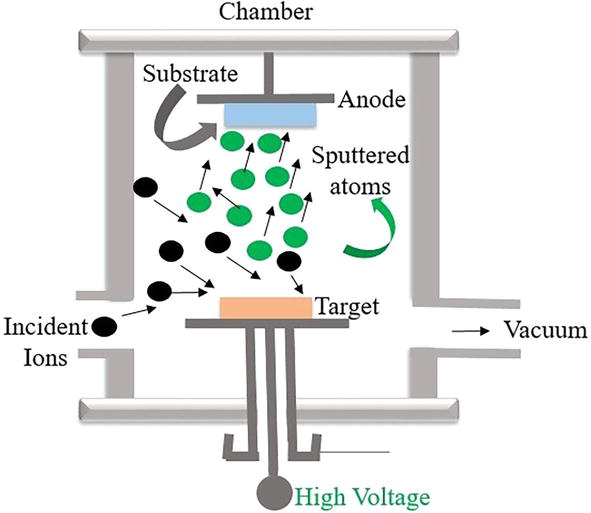
</div>

<div align="center">
Figura 1: Diagrama del proceso de sputtering en la configuración usada en el CICIMA.
</div>

Para controlar el espesor de la película resultante, se pueden variar los siguientes parámetros:
* <b>Potencia de la fuente (en W):</b> determina la energía de los iones incidentes.
* <b>Distancia blanco-sustrato (en cm):</b> determina cuánto tienen que recorrer los átomos eyectados antes de llegar a la muestra.
* <b>Presión del gas (en Pa o mTorr):</b> determina la cantidad de partículas del gas presentes en la cámara.

Ahora bien, para aumentar la eficiencia de este proceso se suele recurrir a la configuración de magnetrón, la cual es la empleada en el sistema del CICIMA. En ella, un conjunto de imanes colocado detrás del blanco superpone un campo magnético al campo eléctrico del cátodo. Este campo confina a los electrones del plasma en trayectorias cicloidales cerca de la superficie del blanco, formando un anillo de electrones atrapados (ver Figura 2). Dicho confinamiento incrementa la probabilidad de que los electrones ionicen más átomos del gas antes de perderse hacia las paredes de la cámara, lo que eleva la densidad de iones disponibles para el bombardeo (corriente de descarga) y, en consecuencia, la tasa de pulverización, permitiendo operar a presiones más bajas (0,1 a 1 Pa) y con voltajes menores que en un sistema DC simple sin magnetrón [2]. Como consecuencia de esta localización del plasma, las colisiones ocurren de manera concentrada sobre esa región, formando un canal de erosión (racetrack) desde el cual se emite la mayor parte de los átomos del blanco.

<div align="center">
  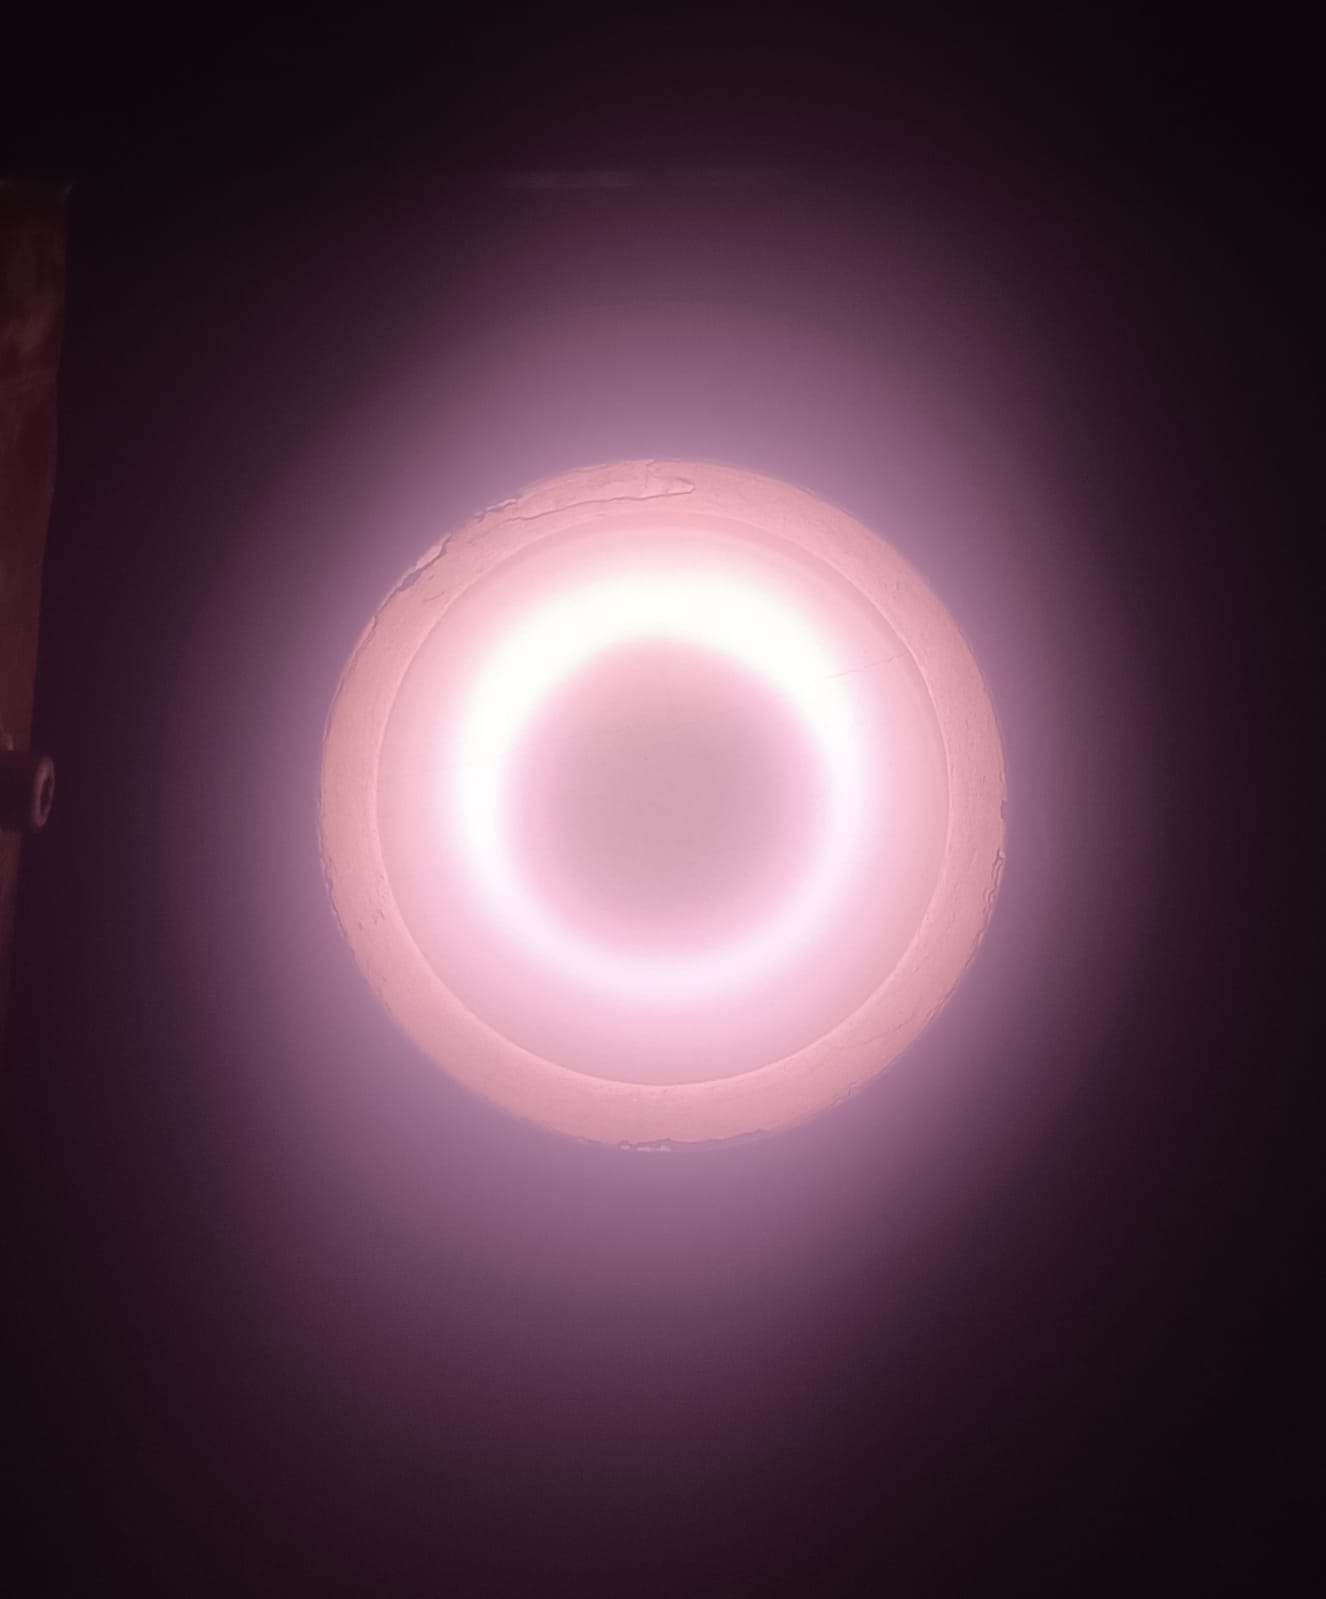
</div>

<div align="center">
Figura 2: Foto del blanco durante la deposición. El anillo brillante es el plasma concentrado sobre el blanco.
</div>

### Estado inicial de los átomos pulverizados

Para poder estudiar el movimiento de los átomos pulverizados, primero se debe conocer su estado inicial tras ser expulsados por los iones incidentes. Por lo tanto, para este proyecto se utilizará la teoría presentada por Rainer Behrisch y Wolfgang Eckstein [3] sobre las posibles energías y posiciones angulares iniciales de cada partícula.

#### Distribución de energía

Cuando un ion de energía $E_0$ colisiona con el blanco, este transfiere parte de su energía al material y provoca una serie de cascadas de colisiones en su interior que pueden terminar en un átomo siendo pulverizado si este llega a la superficie con suficiente energía para superar las fuerzas de enlace superficial. Teóricamente, la cantidad de átomos expulsados $Y$ con una energía cinética $E$ está dada por la siguiente distribución espectral $p(E)$:
$$
\frac{dY}{dE} = p(E) \propto \frac{E}{(E+U)^3}
$$
siendo *U* la energía de enlace superficial (habitualmente asumida como la energía de sublimación).

Normalizando sobre $[0,\infty)$ (no hay energías negativas), esta distribución queda:

$$
p(E) = \frac{2\,U\,E}{(E+U)^3}
$$

Nótese que para $E \gg U$, $p(E)$ decae asintóticamente como $E^{-2}$ sin anularse estrictamente, lo que implicaría en teoría que no existe un techo energético para la partícula pulverizada, por más improbable que sea el evento. No obstante, en la práctica ningún átomo puede ser eyectado con una energía superior a la máxima energía transferible durante la colisión con el ion incidente. Por lo tanto, existe un límite físico para la energía cinética de emisión, el cual está determinado por:

$$
E_{max} = \gamma E_0, \qquad \gamma = \frac{4M_1M_2}{(M_1+M_2)^2}
$$

donde $M_1$ es la masa del ion y $M_2$ la del átomo del blanco.

#### Distribución angular

La cantidad de átomos de material que salen despedidos dentro de un cono espacial específico (ángulo sólido $d\Omega$) está dado por una regla de coseno

$$
\frac{dY}{d\Omega} \propto \cos^y\theta
$$

donde $y$ es un parámetro de ajuste, puesto que muy raras veces se observa una distribución cosenoidal simple a nivel experimental.

Como $d\Omega = \sin\theta d\theta d\phi$, entonces:

$$
\frac{dY}{d\theta d\phi} \propto \cos^y\theta\sin\theta
$$

De esta expresión se deduce que el ángulo azimutal ($\phi$) se encuentra uniformemente distribuido en el intervalo $[0, 2\pi]$, mientras que la densidad de probabilidad para el ángulo polar ($\theta$), respecto a la normal del blanco, está dada por la distribución normalizada en $[0, \pi/2]$ (dado que las partículas solo pueden ser eyectadas hacia el hemisferio superior):

$$
p(\theta) = (y+1)\cos^y\theta\sin\theta
$$

### Rendimiento

Para determinar la cantidad de átomos que llegan al sustrato por segundo, es necesario calcular primero cuántos átomos son pulverizados por unidad de tiempo. El punto de partida es la corriente de descarga $I$, un parámetro medible experimentalmente, a partir del cual el número de iones que inciden sobre el blanco por segundo viene dado por:

$$
\dot{N}_{\text{iones}} = \frac{I}{q}
$$

donde $q$ es la carga del ión. Al multiplicar esta tasa por el rendimiento de pulverización $S(E_0)$ (cuántos átomos del material son expulsados por cada ion incidente) se obtiene la cantidad de átomos pulverizados por segundo:

$$
\dot{N}_{\text{pulverizados}} = \dot{N}_{\text{iones}} \cdot S(E) = \frac{I}{q}\, S(E_0)
$$

Ahora bien, el rendimiento de pulverización a incidencia normal viene dado por la siguiente expresión semiempírica general [4]:

$$
S(E_0) = \frac{0.042}{U}\, \frac{\alpha(M_s/M_g)\, S_n(E_0)}{1 + 0.35\, U\, \hat{s}_e(\epsilon)} \left[ 1 - \left( \frac{E_{th}}{E_0} \right)^{1/2} \right]^{2}
$$

donde:

- $E_0$: energía del ion incidente.
- $U$: energía de enlace superficial del blanco .
- $S_n(E_0)$: sección eficaz de frenado nuclear.
- $\hat{s}_e(\epsilon)$: sección eficaz reducida de frenado electrónico.
- $E_{th}$: energía umbral de pulverización.
- $\alpha(M_s/M_g)$: función adimensional dependiente de la relación de masas blanco/ion ($M_s/M_g$).

#### Frenado nuclear $S_n(E)$

Para poder determinar esta expresión, primero se debe definir la energía reducida de Lindhard $\epsilon$ [5]:

$$
\epsilon = \frac{M_s}{M_g + M_s}\, \frac{a_{TF}}{Z_g Z_s e^{2}}\, E_0
$$

donde $Z_g$ y $Z_s$ son los números atómicos del ion y del blanco, respectivamente; $e$ es la carga elemental; y $a_{TF}$ es el radio de apantallamiento de Thomas-Fermi:

$$
a_{TF} = \frac{0.8853\, a_0}{\left( Z_g^{2/3} + Z_s^{2/3} \right)^{1/2}}
$$

Por su parte, la sección eficaz de frenado nuclear $S_n(E)$ se obtiene mediante la aproximación analítica de Lindhard [5]:

$$
S_n(E) = 4\pi a_{TF} Z_g Z_s e^{2} \left( \frac{M_g}{M_g + M_s} \right) s_n(\epsilon)
$$

donde la sección reducida $s_n(\epsilon)$ está parametrizada como [4]:

$$
s_n(\epsilon) = \frac{3.441\, \sqrt{\epsilon}\, \ln(\epsilon + 2.718)}{1 + 6.355\, \sqrt{\epsilon} + \epsilon\, \left[ -1.708 + 6.882\, \sqrt{\epsilon} \right]}
$$

#### Corrección por frenado inelástico / electrónico ($\hat{s}_e$)

El denominador $\left[ 1 + 0.35\, U\, \hat{s}_e(\epsilon) \right]$ desacopla la contribución electrónica para evitar sobreestimaciones en iones ligeros. La sección eficaz reducida de frenado electrónico $\hat{s}_e(\epsilon)$ es [4]:

$$
\hat{s}_e(\epsilon) = k\, \sqrt{\epsilon}
$$

con la constante $k$ definida por:

$$
k = Z_g^{1/6}\, \frac{0.0793\, (Z_g Z_s)^{1/2}\, (M_g + M_s)^{3/2}}{\left( Z_g^{2/3} + Z_s^{2/3} \right)^{3/4} M_g^{3/2} M_s^{1/2}}
$$

#### Parámetro $\alpha$

El factor $\alpha(M_s/M_g)$ sigue la siguiente aproximación ajustada por mínimos cuadrados [4]:

$$
\alpha =
\begin{cases}
0.10 + 0.155\, \left( \dfrac{M_s}{M_g} \right)^{0.73} & \text{para } \dfrac{M_s}{M_g} \leq 50 \\[10pt]
0.321 + 0.0332\, \left( \dfrac{M_s}{M_g} \right)^{1.1} & \text{para } \dfrac{M_s}{M_g} > 50
\end{cases}
$$

#### Energía umbral de pulverización $E_{th}$

Esta energía se determina mediante la siguiente expresión [4]:

$$
E_{th} = \xi_{II} U
$$

donde la razón umbral relativa $\xi_{II} = E_{th} /U$ se define analíticamente mediante:

$$
\xi_{II} = \frac{1.5}{\gamma} \left[ 1 + 1.38\, \left( \frac{M_g}{M_s} \right)^{h} \right]^{2}
$$

con $\gamma$ el factor de transferencia cinemática máxima:

$$
\gamma = \frac{4 M_g M_s}{(M_g + M_s)^{2}}
$$

y con los exponentes discontinuos:

$$
h =
\begin{cases}
0.834 & \text{para } M_s > M_g \\[6pt]
0.18 & \text{para } M_s < M_g
\end{cases}
$$

### Movimiento de las partículas

Como los átomos del material, una vez expulsados, deben desplazarse a través del gas, resulta conveniente estudiar su movimiento por medio de la teoría cinética de gases, cambiando su trayectoria tras cada colisión de acuerdo a la mecánica clásica. Ahora bien, debido a la naturaleza del proceso y para facilitar el tratamiento del problema, se pueden hacer las siguientes suposiciones [1]:

* Como la concentración de partículas pulverizadas es muy pequeña en comparación a la concentración del gas de fondo, se asume que estas partículas únicamente colisionan con los átomos del gas.
* La distribución del gas es constante en tiempo y el espacio, tomando la presión del gas como constante.
* Debido a la baja concentración de partículas pulverizadas cargadas (grado de ionización típico de $10^{-3}-10^{-4}$) en comparación con las partículas neutras, se desprecia su presencia y las interacciones no elásticas.

#### Camino libre

La distancia $d$ después de una colisión que puede recorrer un átomo pulverizado antes de volver a colisionar se define como camino libre. De la teoría cinética de gases, se sabe que su valor está determinada por medio de la siguiente distribución [6]:

$$
p(d) = \frac{1}{\lambda} e^{-x/\lambda}
$$

siendo $\lambda$ el camino libre medio.

Para el caso de un átomo de masa $M_s$ y radio $r_s$ que se desplaza a través de un gas de masa $M_g$ y radio $r_g$, el camino libre medio viene dado por [1]:

$$
\lambda^{-1} = 4\sqrt{2}\,\pi\,\frac{P_s}{kT}\,r_s^{2} + \pi\,\frac{P_g}{kT}\,(r_s + r_g)^{2}\left(1 + \frac{M_s}{M_g}\right)^{1/2}
$$

donde $P_s$ y $P_g$ son las presiones parciales de los átomos pulverizados y del gas, respectivamente, $k$ es la constante de Boltzmann y $T$ es la temperatura del sistema.

El primer término de esta expresión describe la interacción entre las propias partículas pulverizadas, por lo que puede despreciarse. Por otro lado, se ha demostrado empíricamente que el camino libre medio depende de la energía de la partícula, de modo que debe multiplicarse por un factor $E^{a}$, donde $a = 0$ si $E < 1\ \text{eV}$ y $a = 0{,}29$ si $E > 1\ \text{eV}$ [1]:

$$
\lambda = E^{a} \Bigg/ \left( \pi\,\frac{P_g}{kT}\,(r_s + r_g)^{2}\left(1 + \frac{M_s}{M_g}\right)^{1/2} \right) 
$$

#### Potencial de interacción

Para describir la interacción entre los átomos del gas y los átomos pulverizados (con números atómicos $Z_g$ y $Z_s$, respectivamente), se recurre a un potencial de Coulomb apantallado:

$$
V(r) = \frac{Z_s Z_g e^{2}}{r}\, g(r)
$$

donde la función $g(r)$ introduce el efecto de apantallamiento de los electrones y permite representar de forma más precisa la interacción real entre ambos átomos. Para este tipo de aplicaciones se emplea habitualmente la función de apantallamiento de Molière:

$$
g(r) = 0.35\,\exp\left(-0.3\frac{r}{a_F}\right) + 0.55\,\exp\left(-1.2\frac{r}{a_F}\right) + 0.1\,\exp\left(-6\frac{r}{a_F}\right)
$$

siendo $a_F$ la longitud de apantallamiento de Firsov [7]:

$$
a_F = \frac{0.4685}{\left(Z_s^{1/2} + Z_g^{1/2}\right)^{2/3}}
$$

#### Colisiones

De acuerdo con el tratamiento clásico de las colisiones elásticas, el ángulo de deflexión relativo en el sistema del centro de masas viene dado por [8]:

$$
\theta_{\text{cm}} = \frac{\pi}{2} - b \int_{r_0}^{\infty} \frac{dr}{r^{2}\left\{1 - \left[V(r)/E_{\text{cm}}\right] - \left(b^{2}/r^{2}\right)\right\}^{1/2}}
$$

donde la distancia de máximo acercamiento $r_0$ se determina implícitamente a partir de la conservación del momento y la energía:

$$
b^{2} = r_{0}^{2}\left(1 - \frac{V(r_0)}{E_{\text{cm}}}\right)
$$

Aquí, $b$ es el parámetro de impacto, $r$ la distancia interatómica, $V(r)$ el potencial de interacción y $E_{\text{cm}}$ la energía de la partícula pulverizada en el sistema del centro de masas, dada por [8]:

$$
E_{\text{cm}} = \left(\frac{M_g}{M_s + M_g}\right) E_{\text{lab}}
$$

Ahora bien, conocido $\theta_{\text{cm}}$, el nuevo ángulo polar en el sistema del laboratorio $\theta_{\text{lab}}$ viene dado por:

$$
\theta_{\text{lab}} = \arctan\left(\frac{\sin\theta_{\text{cm}}}{\cos\theta_{\text{cm}} + M_s/M_g}\right)
$$

mientras que el nuevo ángulo azimutal $\phi_{\text{lab}}$ puede tomar cualquier valor en $[0, 2\pi]$. Asimismo, la energía de la partícula tras la colisión es:

$$
E_{\text{labnew}} = E_{\text{lab}}\left(1 - \frac{2(1 - \cos\theta_{\text{cm}})M_g M_s}{(M_s + M_g)^{2}}\right)
$$

Dado que la masa del gas (habitualmente Ar) suele ser menor que la del átomo pulverizado y que el gas se desplaza a una velocidad mucho menor, cada colisión frena progresivamente a la partícula hasta que su energía cinética se vuelve comparable a la del gas de fondo y se termaliza. A partir de ese momento, la partícula deja de seguir una trayectoria balística y pasa a moverse como parte del gas, describiendo un movimiento browniano [1,6].

## <b> ¿Cómo se aplica la técnica de Monte Carlo al problema? </b> 

El método de Monte Carlo consiste en aproximar la solución de un problema mediante el muestreo repetido de variables aleatorias, en lugar de resolver de forma exacta y determinista todas las ecuaciones que gobiernan el sistema. A raíz de esto, se pretende utilizar la teoría presentada anteriormente para simular una muestra representativa de trayectorias individuales, cada una generada muestreando aleatoriamente las distribuciones de probabilidad correspondientes paso a paso, para luego obtener el perfil de espesor a partir de la estadística de dicha muestra.

### Muestreo de variables aleatorias

Para muestrear las distintas variables de interés a partir de sus distribuciones de probabilidad, se empleará el método de la transformada inversa, ya que todas ellas admiten una función de distribución acumulada (CDF) con forma analítica conocida. A continuación se presentan las expresiones para muestrear cada variable, donde $u$ denota una variable aleatoria uniformemente distribuida en $[0,1]$.

#### Energía inicial

La energía cinética inicial de los átomos pulverizados será:

$$
E = \frac{U\sqrt{u}}{1 - \sqrt{u}}
$$

Sin embargo, como se indicó en el marco teórico, esta expresión tiene un soporte infinito ($E \in [0, \infty)$), por lo que debe truncarse para que solo tome valores entre $0$ y $E_{max} = \gamma E_0$. Para ello, se define la densidad truncada conservando las proporciones relativas de $p(E)$ y normalizando sobre el nuevo dominio:

$$
\tilde{p}(E) = \frac{p(E)}{\displaystyle\int_{0}^{E_{max}} p(E')\, dE'} = \frac{p(E)}{F(E_{max})}, \qquad E \in [0, E_{max}]
$$

Integrando se obtiene la acumulada truncada $\tilde{F}(E) = F(E)/F(E_{max})$, que satisface $\tilde{F}(0)=0$ y $\tilde{F}(E_{max})=1$. Aplicando la transformada inversa, $u = \tilde{F}(E)$, el valor de $u'$ que debe sustituirse en la expresión inicial de $E$ es:

$$
u' = u \cdot F(E_{max}) = u \left( \frac{E_{max}}{E_{max} + U} \right)^{2}
$$


#### Ángulo polar de eyección

El ángulo polar inicial será:

$$
\theta = \arccos\left( u^{\frac{1}{y + 1}} \right)
$$

#### Camino libre

El camino libre de cada partícula será:

$$
d = -\lambda \ln(1 - u) = \lambda \ln\left( \frac{1}{1 - u} \right).
$$

#### Parámetro de impacto

Siguiendo el mismo tratamiento que Mahieu et al [1] para el parámetro de impacto, para cada colisión se determinará aleatoriamente un valor entre 0 y un $b_{max}$ para el cual la deflexión de la partícula es despreciable. Desde la perspectiva del átomo de gas de fondo, la partícula incidente "ve" un blanco circular de radio $b_{max}$, y cualquier punto dentro de ese círculo tiene la misma probabilidad de ser atravesado. En consecuencia, la probabilidad de que la colisión ocurra a una distancia $b$ del centro no depende de $b$ en sí, sino de cuánta superficie del blanco se encuentra a esa distancia particular: un anillo cercano al centro ($b \approx 0$) abarca muy poca área, mientras que un anillo cercano al borde ($b \approx b_{max}$) abarca un área mucho mayor.

Especificamente, para un anillo de radio $b$ y espesor infinitesimal $db$, su área es $2\pi b\, db$, mientras que el área total del círculo es $\pi b_{max}^{2}$. La probabilidad elemental de que la colisión ocurra a una distancia entre $b$ y $b + db$ es entonces la razón entre ambas áreas:

$$
p(b)\, db = \frac{2\pi b\, db}{\pi b_{max}^{2}} = \left( \frac{2b}{b_{max}^{2}} \right) db
$$

de donde se obtiene la densidad de probabilidad

$$
p(b) = \frac{2b}{b_{max}^{2}}, \qquad 0 \leq b \leq b_{max}
$$

Aplicando el método de la transformada inversa se obtiene:

$$
b = b_{max} \sqrt{u}
$$


### Estructura general del algoritmo de simulación

Con estas herramientas de muestreo, la simulación de una película depositada se pretende construir repitiendo, para un número grande $N$ de átomos independientes, el siguiente procedimiento:

1. **Estado inicial:** se muestrea la posición de origen del átomo sobre el blanco, así como su energía $E$ y ángulo polar de eyección $\theta$ a partir de las distribuciones correspondientes, y su ángulo azimutal $\phi$ de forma uniforme.

2. **Transporte:** mientras la partícula no haya alcanzado el sustrato, las paredes de la cámara, o un estado termalizado, se muestrea un camino libre $d$, se desplaza la partícula en línea recta esta distancia, y se determina el resultado de la colisión con un átomo del gas muestreando un parámetro de impacto $b$ y obteniendo el ángulo de deflexión $\theta_{cm}$ correspondiente, con lo cual se actualizan la dirección ($\theta_{lab}$, $\phi_{lab}$) y la energía de la partícula.

3. **Terminalización o registro:** si la energía cinética de la partícula cae por debajo de un umbral (comparable a la energía térmica del gas de fondo), esta se considera termalizada y su posición final se determina mediante una caminata aleatoria; en caso contrario, la trayectoria continúa hasta que la partícula impacte el sustrato o abandone el volumen de simulación, momento en el cual se registra su posición de llegada.

4. **Acumulación estadística:** este proceso se repite para los $N$ átomos, y la posición de impacto de cada uno se acumula en un histograma espacial sobre el sustrato, el cual constituye el perfil de espesor simulado de la película. El espesor a un tiempo dado se calcula con la tasa de pulverización deducida anteriormente.

## <b> Referencias </b> 

[1] Mahieu, S., Buyle, G., Depla, D., Heirwegh, S., Ghekiere, P., & De Gryse, R. (2006). Monte Carlo simulation of the transport of atoms in DC magnetron sputtering. *Nuclear Instruments and Methods in Physics Research B*, 243, 313–319.

[2] Wasa, K., Kitabatake, M., & Adachi, H. (2012). *Handbook of Sputtering Technology* (2nd ed.). William Andrew.

[3] Behrisch, R., & Eckstein, W. (Eds.). (2007). *Sputtering by Particle Bombardment: Experiments and Computer Calculations from Threshold to MeV Energies*. Springer.

[4] Yamamura, Y., Matsunami, N., & Itoh, N. (1983). Theoretical studies on an empirical formula for sputtering yield at normal incidence. *Radiation Effects*, 71, 65–86.

[5] Sigmund, P. (1969). Theory of sputtering. I. Sputtering yield of amorphous and polycrystalline targets. *Physical Review*, 184, 383–416.

[6] Kennard, E. H. (1938). *Kinetic Theory of Gases: With an Introduction to Statistical Mechanics*. McGraw-Hill.

[7] Takeuchi, W. (2013). Evaluation of screening length corrections for interaction potentials in impact-collision ion scattering spectroscopy. *Nuclear Instruments and Methods in Physics Research B*, 313, 33–39.

[8] Goldstein, H., Poole, C. P., & Safko, J. L. (2002). *Classical Mechanics* (3rd ed.). Addison-Wesley.